In [1]:
import matplotlib
import matplotlib.pyplot as plt
# import seaborn as sns
import numpy as np
import torch
from PIL import Image

In [5]:
preds_history = np.load("/data/preds_hist.npy", allow_pickle=True)

targets_history = np.load("/data/target_hist.npy", allow_pickle=True)

In [9]:
preds_history

array({'aro_t2m_2m': tensor([[[[-1.9486, -2.1749, -2.0187,  ..., -0.6457, -0.6089, -0.5720],
          [-1.7991, -2.7344, -2.7395,  ..., -1.0154, -0.5297, -0.3735],
          [-1.5834, -2.2783, -2.6390,  ..., -0.5870, -0.8096, -0.6611],
          ...,
          [-1.1628, -1.6205, -1.6132,  ..., -2.6911, -3.0901, -2.8084],
          [-1.8371, -1.2182, -1.5697,  ..., -2.0643, -2.4709, -1.8836],
          [-1.2588, -1.2080, -1.3318,  ..., -1.9043, -2.6364, -2.0107]]],


        [[[-1.9485, -2.1748, -2.0187,  ..., -0.6457, -0.6087, -0.5721],
          [-1.7990, -2.7344, -2.7394,  ..., -1.0158, -0.5297, -0.3735],
          [-1.5833, -2.2784, -2.6393,  ..., -0.5872, -0.8094, -0.6610],
          ...,
          [-1.1629, -1.6205, -1.6132,  ..., -2.6910, -3.0904, -2.8086],
          [-1.8373, -1.2184, -1.5696,  ..., -2.0644, -2.4709, -1.8838],
          [-1.2588, -1.2079, -1.3319,  ..., -1.9044, -2.6366, -2.0106]]],


        [[[-1.7502, -1.8616, -1.4495,  ..., -0.2068, -0.2537, -0.2659],
     

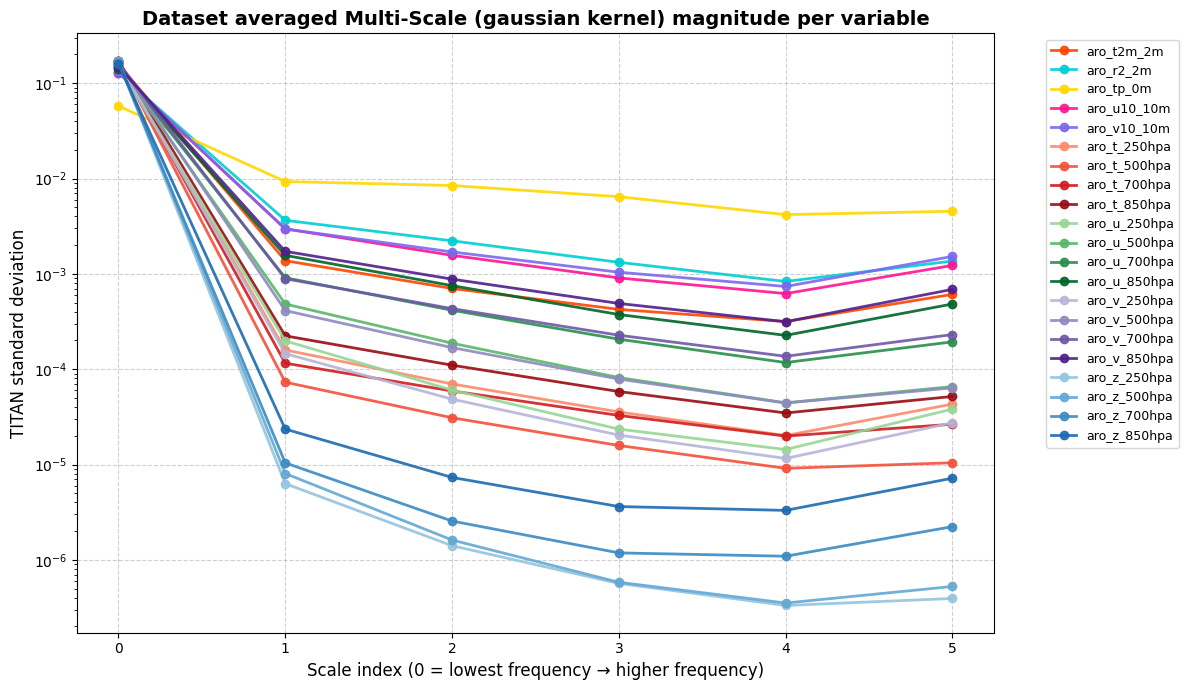

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors

# Load multi-scale stats
stats = np.load("/path2stats/multi_scale_gk_stats.npy", allow_pickle=True).item()

# Variables in your order
variables = [
    'aro_t2m_2m', 'aro_r2_2m', 'aro_tp_0m', 'aro_u10_10m', 'aro_v10_10m',
    'aro_t_250hpa','aro_t_500hpa','aro_t_700hpa','aro_t_850hpa',
    'aro_u_250hpa','aro_u_500hpa','aro_u_700hpa','aro_u_850hpa',
    'aro_v_250hpa','aro_v_500hpa','aro_v_700hpa','aro_v_850hpa',
    'aro_z_250hpa','aro_z_500hpa','aro_z_700hpa','aro_z_850hpa'
]

n_scales = len(stats[variables[0]]["std"])

# Build variance array: shape (n_scales, n_vars)
variances = np.stack(
    [[(stats[var]["std"][i].item() ** 2) for i in range(n_scales)] for var in variables],
    axis=1
)  # (n_scales, n_vars)

# --- Define color mapping by groups ---
color_map = {}

# Surface variables → Blues
surface_vars = variables[:5]
surface_colors = ["#FF4500", "#00CED1", "#FFD700", "#FF1493", "#7B68EE"]
for var, c in zip(surface_vars, surface_colors):
    color_map[var] = c

# Temperature hPa → Reds
t_vars = [v for v in variables if "_t_" in v and "hpa" in v]
reds = cm.Reds(np.linspace(0.4, 0.9, len(t_vars)))
for var, c in zip(t_vars, reds):
    color_map[var] = c

# U wind hPa → Greens
u_vars = [v for v in variables if "_u_" in v and "hpa" in v]
greens = cm.Greens(np.linspace(0.4, 0.9, len(u_vars)))
for var, c in zip(u_vars, greens):
    color_map[var] = c

# V wind hPa → Purples
v_vars = [v for v in variables if "_v_" in v and "hpa" in v]
purples = cm.Purples(np.linspace(0.4, 0.9, len(v_vars)))
for var, c in zip(v_vars, purples):
    color_map[var] = c

# Z hPa → Oranges, but last four special fancy colors
z_vars = [v for v in variables if "_z_" in v and "hpa" in v]
oranges = cm.Oranges(np.linspace(0.4, 0.8, len(z_vars)))
# Override with strong fancy colors
blues = cm.Blues(np.linspace(0.4, 0.9, len(surface_vars)))
for var, c in zip(z_vars, blues):
    color_map[var] = c

# --- Plot ---
plt.figure(figsize=(12, 7))
scales = list(range(n_scales))

for j, var in enumerate(variables):
    plt.plot(
        scales, variances[:, j],
        marker="o", markersize=6, linewidth=2,
        color=color_map[var], label=var, alpha=0.9
    )

plt.xlabel("Scale index (0 = lowest frequency → higher frequency)", fontsize=12)
plt.ylabel("TITAN standard deviation", fontsize=12)
plt.yscale("log")
plt.title("Dataset averaged Multi-Scale (gaussian kernel) magnitude per variable", fontsize=14, fontweight="bold")
plt.grid(True, linestyle="--", alpha=0.6)

# Fancy legend outside
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left", fontsize=9, frameon=True)
plt.tight_layout()
plt.show()


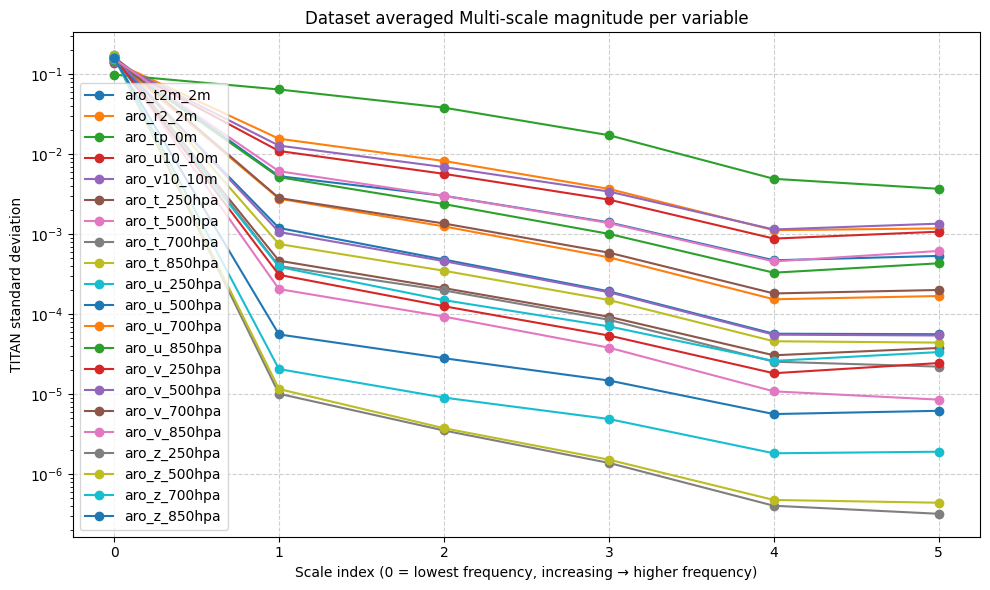

In [18]:
import numpy as np
import matplotlib.pyplot as plt

# Load multi-scale stats
stats = np.load("/path2stats/multi_scale_stats.npy", allow_pickle=True).item()

# Extract variables and scales
variables = [k for k in stats.keys() if "aro" in k]
n_scales = len(stats[variables[0]]["std"])

# Build variance array: shape (n_scales, n_vars)
variances = np.stack(
    [[(stats[var]["std"][i].item() ** 2) for i in range(n_scales)] for var in variables],
    axis=1
)  # (n_scales, n_vars)

# Plot
plt.figure(figsize=(10, 6))
scales = list(range(n_scales))  # slice index (0..5 if max_scale_power=5)

for j, var in enumerate(variables):
    plt.plot(scales, variances[:, j], marker="o", label=var)

plt.xlabel("Scale index (0 = lowest frequency, increasing → higher frequency)")
plt.ylabel("TITAN standard deviation")
plt.yscale("log")
plt.title("Dataset averaged Multi-scale magnitude per variable")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()


In [19]:
variables

['aro_t2m_2m',
 'aro_r2_2m',
 'aro_tp_0m',
 'aro_u10_10m',
 'aro_v10_10m',
 'aro_t_250hpa',
 'aro_t_500hpa',
 'aro_t_700hpa',
 'aro_t_850hpa',
 'aro_u_250hpa',
 'aro_u_500hpa',
 'aro_u_700hpa',
 'aro_u_850hpa',
 'aro_v_250hpa',
 'aro_v_500hpa',
 'aro_v_700hpa',
 'aro_v_850hpa',
 'aro_z_250hpa',
 'aro_z_500hpa',
 'aro_z_700hpa',
 'aro_z_850hpa']

In [2]:
aro_t = torch.tensor(np.load("/arome/data/2024-01-09_06h00/aro_t2m_2m.npy"))
arot1 = torch.tensor(np.load("/arome/data/2024-01-09_07h00/aro_t2m_2m.npy"))


In [3]:
import xarray as xr

data_path = "/era5/"
db = xr.open_zarr(data_path)
ds=db["2m_temperature"]

ds['longitude'] = xr.where(ds['longitude'] > 180, ds['longitude'] - 360, ds['longitude'])
ds = ds.sortby('longitude')
if 'longitude' in ds.coords:
    ds = ds.reindex(longitude=ds['longitude'])

lon_min, lon_max = -12., 16.
lat_min, lat_max = 37.5, 55.4  # FRANCE

resolution = 0.25
era5_to_arome_lat = np.arange(lat_min, lat_max , resolution)
era5_to_arome_lon = np.arange(lon_min, lon_max , resolution)

subset_ds = ds.sel(
    latitude=slice(era5_to_arome_lat.max().item(), era5_to_arome_lat.min().item()),
    longitude=slice(era5_to_arome_lon.min().item(), era5_to_arome_lon.max().item()),
    time=slice("2020-06-15T00:00:00.000000000", "2020-12-31T00:00:00.000000000")
)
era5_2mT = np.array(subset_ds.values)

In [7]:
era5_2mT.shape 

(200, 72, 112)

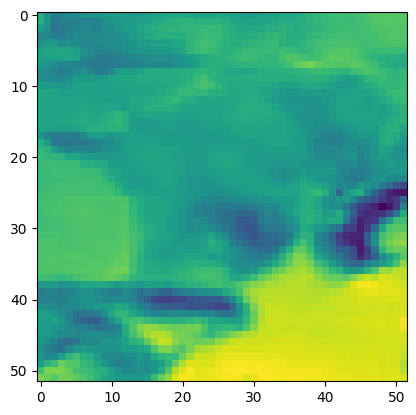

In [12]:
plt.imshow(era5_2mT[0,10:62, 30:82])

In [27]:
x1.shape

torch.Size([512, 640])

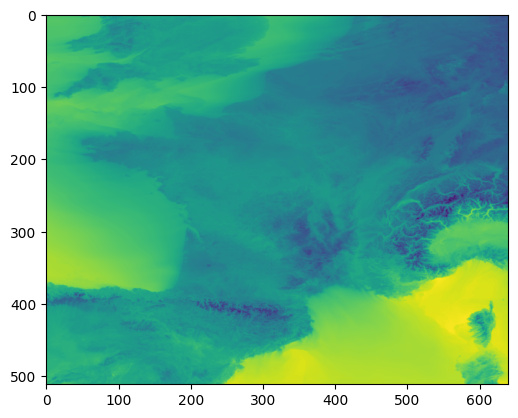

In [6]:
plt.imshow(np.flip(np.array(x1), axis=0))

In [4]:
import torch
import torch.nn.functional as F
import math

def downsample_aro_inputs_gaussian(aro_inputs: torch.Tensor, n: int) -> torch.Tensor:
    """
    Smooth aro_inputs using a Gaussian kernel whose strength corresponds
    to the downsampling factor n (instead of bilinear interpolation).

    Args:
        aro_inputs (Tensor): input of shape (N_lat, N_lon) or (C, N_lat, N_lon).
        n (int): scale factor, e.g. 2, 4, 8 ...

    Returns:
        Tensor: smoothed version of same shape as aro_inputs
    """
    # Handle both 2D (N_lat, N_lon) and 3D (C, N_lat, N_lon)
    if aro_inputs.dim() == 2:
        aro_inputs = aro_inputs.unsqueeze(0).unsqueeze(0)  # (1,1,N_lat,N_lon)
    elif aro_inputs.dim() == 3:
        aro_inputs = aro_inputs.unsqueeze(0)  # (1,C,N_lat,N_lon)
    elif aro_inputs.dim() == 4:
        pass  # already (B,C,N_lat,N_lon)
    else:
        raise ValueError("Input must be 2D, 3D, or 4D tensor")

    B, C, N_lat, N_lon = aro_inputs.shape

    # Map scale factor n -> equivalent Gaussian sigma
    sigma = n / math.sqrt(3.0)

    # Build Gaussian kernel
    kernel_size = int(6 * sigma + 1)
    if kernel_size % 2 == 0:  # ensure odd
        kernel_size += 1

    coords = torch.arange(kernel_size, device=aro_inputs.device, dtype=aro_inputs.dtype) - kernel_size // 2
    g_1d = torch.exp(-0.5 * (coords / sigma) ** 2)
    g_1d /= g_1d.sum()

    # Separable 2D kernel
    g_2d = torch.outer(g_1d, g_1d)
    g_2d /= g_2d.sum()

    # Depthwise conv kernel
    g_kernel = g_2d.view(1, 1, kernel_size, kernel_size).to(aro_inputs.dtype).to(aro_inputs.device)
    g_kernel = g_kernel.repeat(C, 1, 1, 1)  # one kernel per channel

    # Padding for "same" output size
    pad = kernel_size // 2
    aro_inputs_padded = F.pad(aro_inputs, (pad, pad, pad, pad), mode="reflect")

    # Apply depthwise convolution
    smoothed = F.conv2d(aro_inputs_padded, g_kernel, groups=C)

    # Drop back to original shape if needed
    if smoothed.shape[0] == 1 and smoothed.shape[1] == 1:
        smoothed = smoothed.squeeze(0).squeeze(0)  # (N_lat, N_lon)
    elif smoothed.shape[0] == 1:
        smoothed = smoothed.squeeze(0)  # (C, N_lat, N_lon)

    return smoothed


In [14]:
x1 = aro_t

In [17]:
d16=np.array(downsample_aro_inputs_gaussian(x1, n=16))
d8=np.array(downsample_aro_inputs_gaussian(x1, n=8))
d32=np.array(downsample_aro_inputs_gaussian(x1, n=32))

In [16]:
np.sum(d8-d16)

183.466

In [17]:
np.sum(d16[:512,:640]-d32)

313.35217

In [15]:
print(np.min(d8-d16))
print(np.max(d8-d16))
print(np.min(d16[:512,:640]-d32))
print(np.max(d16[:512,:640]-d32))


-3.9382935
2.3893738
-4.598633
2.736786


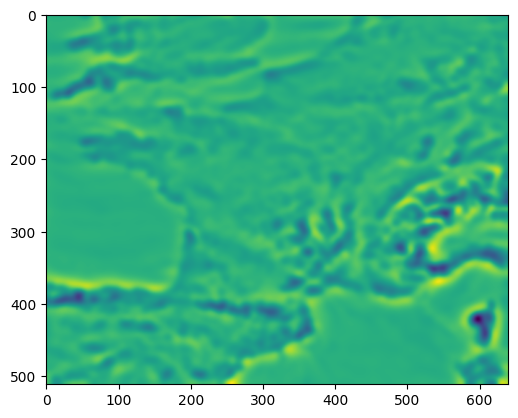

In [18]:
plt.imshow(np.flip(d8-d16, axis=0))

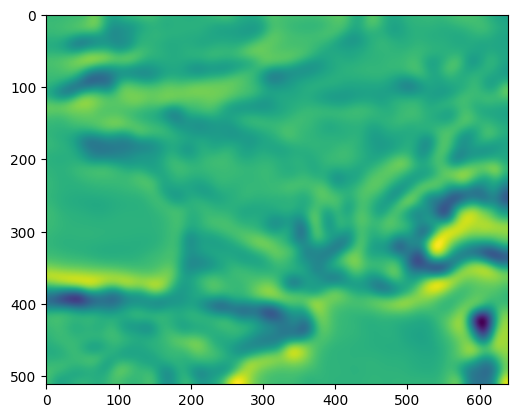

In [19]:
plt.imshow(np.flip(d16[:512,:640]-d32, axis=0))

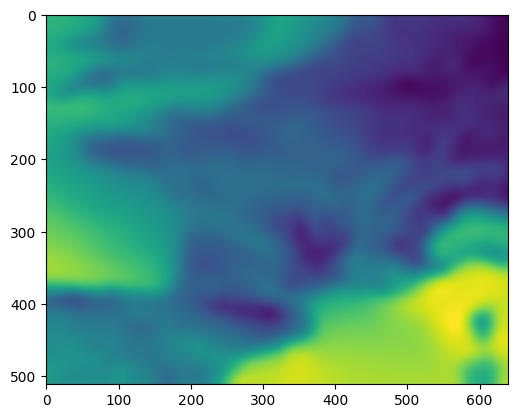

In [20]:
plt.imshow(np.flip(np.array(downsample_aro_inputs_gaussian(x1, n=16)), axis=0))

In [5]:
def downsample_aro_inputs(aro_inputs, n):   
# Compute low-res dimensions
    # Handle both 2D (N_lat, N_lon) and 3D (C, N_lat, N_lon)
    if aro_inputs.dim() == 2:
        aro_inputs = aro_inputs.unsqueeze(0).unsqueeze(0)  # (1,1,N_lat,N_lon)
    elif aro_inputs.dim() == 3:
        aro_inputs = aro_inputs.unsqueeze(0)  # (1,C,N_lat,N_lon)
    elif aro_inputs.dim() == 4:
        pass  # already (B,C,N_lat,N_lon)
    else:
        raise ValueError("Input must be 2D, 3D, or 4D tensor")

    B, C, N_lat, N_lon = aro_inputs.shape

    N_lat_low = N_lat // n
    N_lon_low = N_lon // n

    # Downsample
    aro_inputs_lowres = torch.nn.functional.interpolate(
        aro_inputs, size=(N_lat_low, N_lon_low), mode='bilinear', align_corners=False
    )

    # Upsample back
    smoothed = torch.nn.functional.interpolate(
        aro_inputs_lowres, size=(N_lat, N_lon), mode='bilinear', align_corners=False
    )

    # Drop back to original shape if needed
    if smoothed.shape[0] == 1 and smoothed.shape[1] == 1:
        smoothed = smoothed.squeeze(0).squeeze(0)  # (N_lat, N_lon)
    elif smoothed.shape[0] == 1:
        smoothed = smoothed.squeeze(0)  # (C, N_lat, N_lon)

    return smoothed

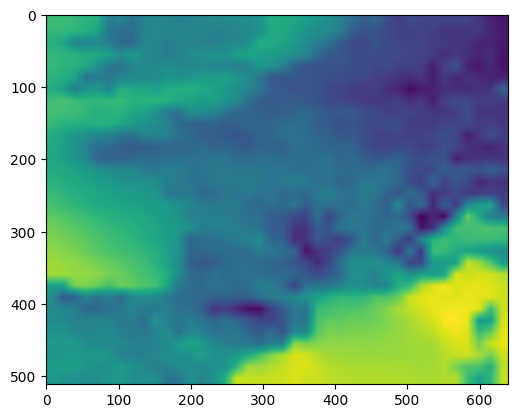

In [47]:
plt.imshow(np.flip(np.array(downsample_aro_inputs(x1, n=16)), axis=0))

In [12]:
era5_t = torch.tensor(era5_2mT[0,10:62, 30:82])
era5_t1 = torch.tensor(era5_2mT[1,10:62, 30:82])

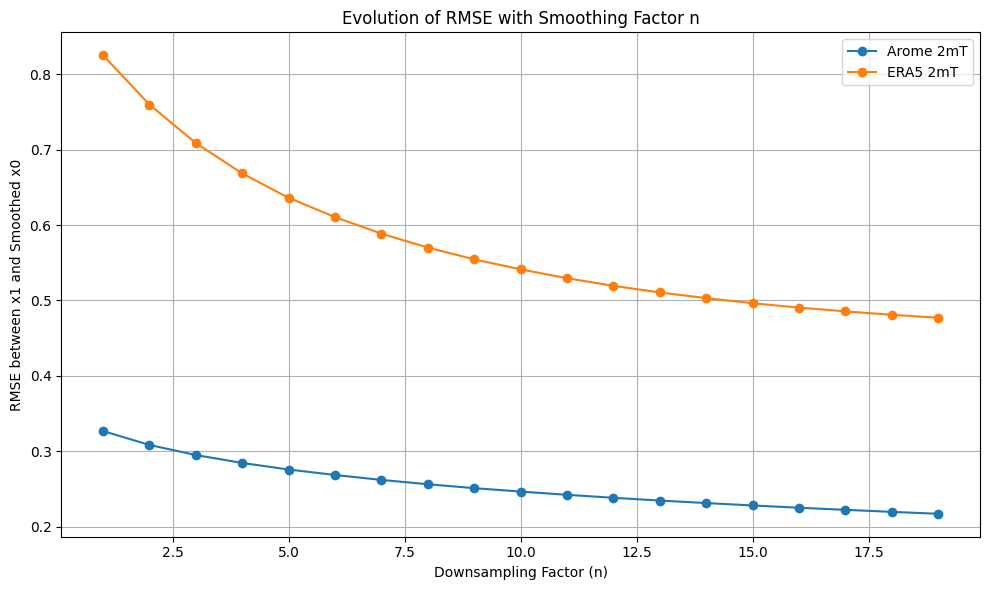

In [15]:
# Compute RMSE between x1 and smoothed x0 for different n
aro_rmse_values = []
era5_rmse_values = []
n_values = range(1, 20)

for n in n_values:
    aro_t_smooth = downsample_aro_inputs_gaussian(aro_t, n)
    aro_t1_smooth = downsample_aro_inputs_gaussian(arot1, n)
    era5_t_smooth = downsample_aro_inputs_gaussian(era5_t, n)
    era5_t1_smooth = downsample_aro_inputs_gaussian(era5_t1, n)
    aro_rmse = torch.sqrt(torch.mean((aro_t_smooth - aro_t1_smooth) ** 2)).item()
    era5_rmse = torch.sqrt(torch.mean((era5_t_smooth - era5_t1_smooth) ** 2)).item()
    aro_rmse_values.append(aro_rmse)
    era5_rmse_values.append(era5_rmse)

# Plot the curve
plt.figure(figsize=(10, 6))
plt.plot(n_values, aro_rmse_values, marker='o', label='Arome 2mT')
plt.plot(n_values, era5_rmse_values, marker='o', label='ERA5 2mT')
plt.xlabel('Downsampling Factor (n)')
plt.ylabel('RMSE between x1 and Smoothed x0')
plt.title('Evolution of RMSE with Smoothing Factor n')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


In [20]:
from PIL import Image
import os

for var in ["tp_0m", "t2m_2m", "u10_10m", "v10_10m"]:
    for period in ["summer", "winter", "spring", "fall"]:

        # Define the image folder and output GIF path
        image_folder = "/path2stats/titan_21var/afcrps_0order_5em4/gif_"+period+"/timestep_evol_per_param"
        output_gif_path = os.path.join(image_folder, "aro_"+var+"_HQ.gif")

        # Generate ordered list of image file paths
        image_paths = [
            os.path.join(image_folder, "aro_"+var+f"_example_1_{i}.png")
            for i in range(1, 42)
        ]

        # Load images
        images = [Image.open(path).convert("RGB") for path in image_paths]

        # Save as high-quality GIF
        images[0].save(
            output_gif_path,
            save_all=True,
            append_images=images[1:],
            duration=200,      # Duration per frame in milliseconds
            loop=0,            # Loop forever
            optimize=True,     # Try to compress
            quality=100,       # Pillow uses 'quality' only for JPEGs, so not relevant here
            disposal=2         # Clear frame before rendering the next (prevents artifacts)
        )

        print(f"GIF saved to: {output_gif_path}")


GIF saved to: /path2stats/titan_21var/afcrps_0order_5em4/gif_summer/timestep_evol_per_param/aro_tp_0m_HQ.gif
GIF saved to: /path2stats/titan_21var/afcrps_0order_5em4/gif_winter/timestep_evol_per_param/aro_tp_0m_HQ.gif
GIF saved to: /path2stats/titan_21var/afcrps_0order_5em4/gif_spring/timestep_evol_per_param/aro_tp_0m_HQ.gif
GIF saved to: /path2stats/titan_21var/afcrps_0order_5em4/gif_fall/timestep_evol_per_param/aro_tp_0m_HQ.gif
GIF saved to: /path2stats/titan_21var/afcrps_0order_5em4/gif_summer/timestep_evol_per_param/aro_t2m_2m_HQ.gif
GIF saved to: /path2stats/titan_21var/afcrps_0order_5em4/gif_winter/timestep_evol_per_param/aro_t2m_2m_HQ.gif
GIF saved to: /path2stats/titan_21var/afcrps_0order_5em4/gif_spring/timestep_evol_per_param/aro_t2m_2m_HQ.gif
GIF saved to: /path2stats/titan_21var/afcrps_0order_5em4/gif_fall/timestep_evol_per_param/aro_t2m_2m_HQ.gif
GIF saved to: /path2stats/titan_21var/afcrps_0order_5em4/gif_summer/timestep_evol_per_param/aro_u10_10m_HQ.gif
GIF saved to: /pa

In [10]:
from PIL import Image
import os

var = "u_850hpa"

# Define the image folder and output GIF path
image_folder = "/scratch/audrena/py4cast_expe/titan_21var/mse_ARPdownscale_5em4_multiscale/test_gifs_aurore2021_6OLTs/timestep_evol_per_param"
output_gif_path = os.path.join(image_folder, "aro_"+var+"_HQ.gif")

# Generate ordered list of image file paths
image_paths = [
    os.path.join(image_folder, "aro_"+var+f"_example_1_{i}.png")
    for i in range(1, 42)
]

# Load images
images = [Image.open(path).convert("RGB") for path in image_paths]

# Save as high-quality GIF
images[0].save(
    output_gif_path,
    save_all=True,
    append_images=images[1:],
    duration=100,      # Duration per frame in milliseconds
    loop=0,            # Loop forever
    optimize=True,     # Try to compress
    quality=100,       # Pillow uses 'quality' only for JPEGs, so not relevant here
    disposal=2         # Clear frame before rendering the next (prevents artifacts)
)

print(f"GIF saved to: {output_gif_path}")

GIF saved to: /scratch/audrena/py4cast_expe/titan_21var/mse_ARPdownscale_5em4_multiscale/test_gifs_aurore2021_6OLTs/timestep_evol_per_param/aro_u_850hpa_HQ.gif


In [5]:
from PIL import Image
import os

vars = ["t_850hpa", "tp_0m", "t2m_2m", "v10_10m", "z_500hpa", "r2_2m"]
# vars = ["t_850hpa", "u_850hpa", "v_850hpa", "z_850hpa"]
for var in vars:
    # Define the image folder and output GIF path
    image_folder = "/scratch/audrena/py4cast_expe/titan_21var/mae2crps_1order_5em4_2M_2BS/test_poesy_ciaran_epoch69/timestep_spread_evol_per_param"
    output_gif_path = os.path.join(image_folder, "pearo_"+var+".gif")
    # Generate ordered list of image file paths
    image_paths = [
    os.path.join(image_folder, "pearo_"+var+f"_example_1_{i}.png")
    for i in range(1, 41)
    ]

    from PIL import Image, ImageSequence
    # Load images
    images = [Image.open(path).convert("RGB") for path in image_paths]
    # Convert all frames to use the same palette (first frame's palette)
    palette_image = images[0].convert("P", palette=Image.ADAPTIVE, colors=256)
    paletted_frames = [img.convert("RGB").quantize(palette=palette_image) for img in images]
    # Save GIF
    paletted_frames[0].save(
        output_gif_path,
        save_all=True,
        append_images=paletted_frames[1:],
        duration=150,
        loop=0,
        optimize=False,  # optimization can sometimes re-map colors
        disposal=2
    )
    print(f"GIF saved to: {output_gif_path}")

GIF saved to: /scratch/audrena/py4cast_expe/titan_21var/mae2crps_1order_5em4_2M_2BS/test_poesy_ciaran_epoch69/timestep_spread_evol_per_param/pearo_t_850hpa.gif
GIF saved to: /scratch/audrena/py4cast_expe/titan_21var/mae2crps_1order_5em4_2M_2BS/test_poesy_ciaran_epoch69/timestep_spread_evol_per_param/pearo_tp_0m.gif
GIF saved to: /scratch/audrena/py4cast_expe/titan_21var/mae2crps_1order_5em4_2M_2BS/test_poesy_ciaran_epoch69/timestep_spread_evol_per_param/pearo_t2m_2m.gif
GIF saved to: /scratch/audrena/py4cast_expe/titan_21var/mae2crps_1order_5em4_2M_2BS/test_poesy_ciaran_epoch69/timestep_spread_evol_per_param/pearo_v10_10m.gif
GIF saved to: /scratch/audrena/py4cast_expe/titan_21var/mae2crps_1order_5em4_2M_2BS/test_poesy_ciaran_epoch69/timestep_spread_evol_per_param/pearo_z_500hpa.gif
GIF saved to: /scratch/audrena/py4cast_expe/titan_21var/mae2crps_1order_5em4_2M_2BS/test_poesy_ciaran_epoch69/timestep_spread_evol_per_param/pearo_r2_2m.gif


In [2]:
from PIL import Image
import os

for var in ["pearo_t2m_2m", "pearo_tp_0m", "pearo_r2_2m", "pearo_v10_10m", "pearo_t_850hpa", "pearo_z_500hpa"]:

    # Define the image folder and output GIF path
    image_folder = "/data/titan_21var/afcrps_0order_5em4/test_poesy_6var_1rlt/timestep_spread_evol_per_param"
    output_gif_path = os.path.join(image_folder, var+".gif")

    # Generate ordered list of image file paths
    image_paths = [
        os.path.join(image_folder, var+f"_example_1_{i}.png")
        for i in range(1, 42)
    ]

    # Load images
    images = [Image.open(path).convert("RGB") for path in image_paths]

    # Save as high-quality GIF
    images[0].save(
        output_gif_path,
        save_all=True,
        append_images=images[1:],
        duration=100,      # Duration per frame in milliseconds
        loop=0,            # Loop forever
        optimize=True,     # Try to compress
        quality=100,       # Pillow uses 'quality' only for JPEGs, so not relevant here
        disposal=2         # Clear frame before rendering the next (prevents artifacts)
    )

    print(f"GIF saved to: {output_gif_path}")


FileNotFoundError: [Errno 2] No such file or directory: '/data/titan_21var/afcrps_0order_5em4/test_poesy_6var_1rlt/timestep_spread_evol_per_param/pearo_t2m_2m_example_1_1.png'